# Checkpoint 2 

## LED vs. laser optotagging

**Data and analysis setup**
Rates use the 8-ms evoked window after pulse onset and the saved matched-candidate and QC flags. Session IDs below 789848216 are labeled LED and IDs at or above it are labeled laser. This cutoff is an unverified hardware proxy throughout the section. Reconnect `WD_BLACK` before running.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
SOURCE = ROOT / "opto_results" / "all_opto_unit_results.csv"
if not SOURCE.is_file():
    raise FileNotFoundError(f"Connect WD_BLACK or set SPIKES2SLOPE_DATA: {SOURCE}")
df = pd.read_csv(SOURCE)
required = {"unit_id", "ecephys_session_id", "cre_line", "evoked_rate_hz",
            "baseline_rate_hz", "n_pulses", "matched_candidate", "snr_qc"}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
assert df.unit_id.is_unique, "Expected one row per unit"
for flag in ["matched_candidate", "snr_qc"]:
    df[flag] = df[flag].astype(str).str.lower().map(
        {"true": True, "false": False, "1": True, "0": False})
    assert df[flag].notna().all(), f"Unexpected values in {flag}"
df["hardware"] = np.where(df.ecephys_session_id < 789848216, "LED", "Laser")
order = ["LED", "Laser"]
colors = {"LED": "#0072B2", "Laser": "#D55E00"}
sns.set_theme(style="whitegrid", context="notebook")
eligible = df.loc[df.snr_qc].copy()
candidates = df.loc[df.matched_candidate].copy()
assert (candidates.snr_qc).all()
session = df.groupby(["ecephys_session_id", "hardware", "cre_line"], as_index=False).agg(
    eligible=("snr_qc", "sum"), candidates=("matched_candidate", "sum"),
    n_pulses=("n_pulses", "first"))
session["yield_pct"] = np.where(session.eligible > 0,
                                100 * session.candidates / session.eligible, np.nan)
means = candidates.groupby("ecephys_session_id").evoked_rate_hz.mean().rename("mean_evoked_hz")
session = session.merge(means, on="ecephys_session_id", how="left")
assert session.groupby("ecephys_session_id").size().eq(1).all()
print(f"{len(session)} sessions, {len(eligible):,} QC-eligible units, {len(candidates):,} candidates.")
print("Hardware assignment: inherited session-period proxy; not independently verified.")

28 sessions, 8,415 QC-eligible units, 1,127 candidates.
Hardware assignment: inherited session-period proxy; not independently verified.


**How many optotagging candidates did each group produce?**
Compare candidate counts and the fraction of QC-eligible units that met the candidate criteria.

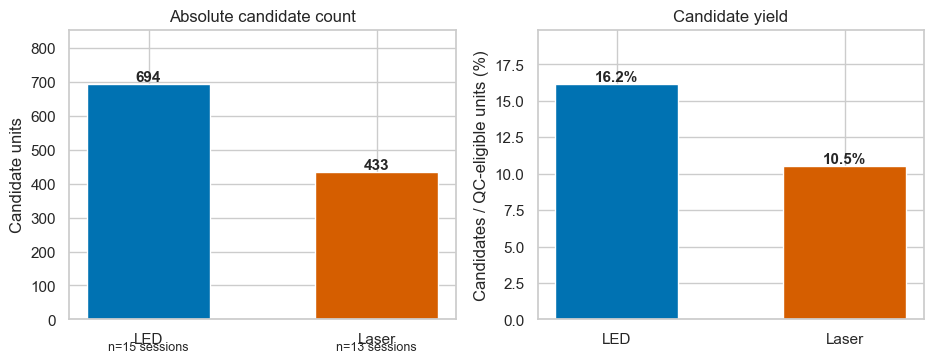

In [2]:
summary = session.groupby("hardware").agg(
    sessions=("ecephys_session_id", "size"),
    eligible=("eligible", "sum"), candidates=("candidates", "sum")).reindex(order)
summary["yield_pct"] = 100 * summary.candidates / summary.eligible
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, col, ylabel in zip(axes, ["candidates", "yield_pct"],
                            ["Candidate units", "Candidates / QC-eligible units (%)"]):
    vals = summary[col].to_numpy()
    ax.bar(order, vals, color=[colors[h] for h in order], width=.54)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.0f}" if col=="candidates" else f"{v:.1f}%",
                ha="center", va="bottom", fontsize=11, weight="bold")
    ax.set(ylabel=ylabel); ax.set_ylim(0, max(vals)*1.23)
axes[0].set_title("Absolute candidate count")
axes[1].set_title("Candidate yield")
for i,h in enumerate(order):
    axes[0].text(i, -max(summary.candidates)*.13, f"n={summary.loc[h,'sessions']} sessions",
                 ha="center", fontsize=9)
fig.tight_layout()
plt.show()

The LED-proxy group yielded **694 candidates across 15 sessions (16.2% of QC-eligible units)**. The laser-proxy group yielded **433 across 13 sessions (10.5%)**. These yields describe how often units passed the selection criteria.

**How do candidate firing-rate distributions compare?**
Bars show the percentage of candidates within each hardware-proxy group in each 8-ms evoked firing-rate bin.

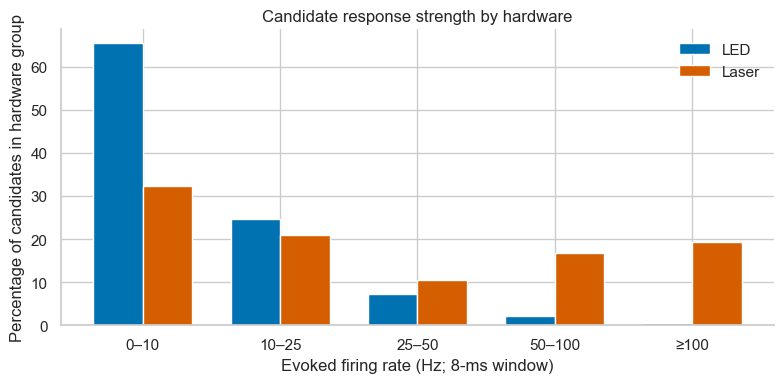

In [3]:
bins = [0, 10, 25, 50, 100, np.inf]
labels = ["0–10", "10–25", "25–50", "50–100", "≥100"]
rate_bins = candidates.assign(rate_bin=pd.cut(candidates.evoked_rate_hz,
                                              bins=bins, labels=labels, right=False))
rate_pct = (pd.crosstab(rate_bins.hardware, rate_bins.rate_bin, normalize="index")
              .reindex(index=order, columns=labels, fill_value=0) * 100)
x = np.arange(len(labels))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4))
for j,h in enumerate(order):
    bars = ax.bar(x + (j-0.5)*width, rate_pct.loc[h], width, label=h, color=colors[h])
ax.set_xticks(x, labels)
ax.set(xlabel="Evoked firing rate (Hz; 8-ms window)",
       ylabel="Percentage of candidates in hardware group",
       title="Candidate response strength by hardware")
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
plt.show()

The pooled candidate median was **5.56 Hz for LED** and **21.67 Hz for laser**. These distributions describe individual candidates, which are nested within recording sessions.

**Is the session-level firing-rate difference statistically supported?**
Each point is a session mean across candidates. Diamonds show the group means and whiskers show 95% confidence intervals. Welch compares arithmetic means, and Mann–Whitney compares rank distributions.

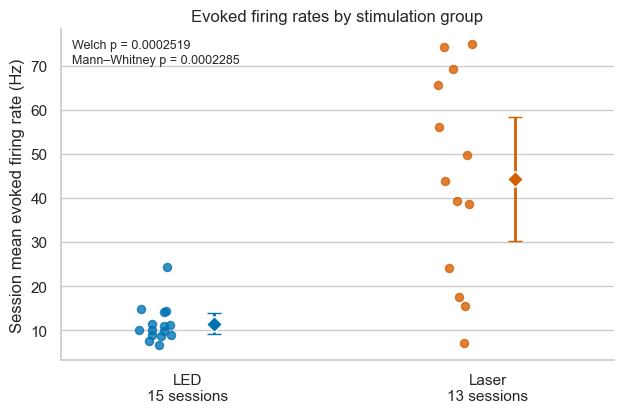

In [4]:
rate_sessions = session.dropna(subset=["mean_evoked_hz"]).copy()
rate_groups = {h: rate_sessions.loc[rate_sessions.hardware.eq(h), "mean_evoked_hz"]
               for h in order}

s = session.dropna(subset=["mean_evoked_hz"]).copy()
a = s.loc[s.hardware.eq("LED"), "mean_evoked_hz"].to_numpy()
b = s.loc[s.hardware.eq("Laser"), "mean_evoked_hz"].to_numpy()
test = stats.ttest_ind(a, b, equal_var=False)

def welch_session_comparison(led, laser, result=None):
    led, laser = np.asarray(led), np.asarray(laser)
    difference = led.mean() - laser.mean()
    v_led = led.var(ddof=1) / len(led)
    v_laser = laser.var(ddof=1) / len(laser)
    dof = (v_led + v_laser)**2 / (
        v_led**2 / (len(led) - 1) + v_laser**2 / (len(laser) - 1))
    margin = stats.t.ppf(.975, dof) * np.sqrt(v_led + v_laser)
    if result is None:
        result = stats.ttest_ind(led, laser, equal_var=False)
    return {"difference_hz": difference, "ci_low_hz": difference - margin,
            "ci_high_hz": difference + margin, "df": dof,
            "t": result.statistic, "p": result.pvalue}


led_rates, laser_rates = (rate_groups[h] for h in order)
welch_rates = welch_session_comparison(led_rates, laser_rates, result=test)
rank_rates = stats.mannwhitneyu(led_rates, laser_rates, alternative="two-sided",
                               method="asymptotic")
def plot_session_rates(ax, rows, rng):
    for i, h in enumerate(order):
        values = rows.loc[rows.hardware.eq(h), "mean_evoked_hz"]
        ax.scatter(i + rng.uniform(-.17, -.05, len(values)), values,
                   color=colors[h], s=34, alpha=.78)
        if len(values) >= 2:
            margin = stats.t.ppf(.975, len(values) - 1) * stats.sem(values)
            ax.errorbar(i + .09, values.mean(), yerr=margin, fmt="D", color=colors[h],
                        markeredgecolor="white", markersize=8, capsize=5, linewidth=2)
        elif len(values) == 1:
            ax.plot(i + .09, values.iloc[0], marker="D", color=colors[h])
    counts = rows["hardware"].value_counts()
    ax.set_xticks(range(len(order)), [f"{h}\n{counts.get(h, 0)} sessions" for h in order])
    ax.set(xlim=(-.42, 1.42))
    ax.grid(axis="x", visible=False)


fig, ax = plt.subplots(figsize=(6.4, 4.3))
plot_session_rates(ax, rate_sessions, np.random.default_rng(42))
ax.set(ylabel="Session mean evoked firing rate (Hz)",
       title="Evoked firing rates by stimulation group")
ax.text(.02, .97, f"Welch p = {welch_rates['p']:.4g}\nMann–Whitney p = {rank_rates.pvalue:.4g}",
        transform=ax.transAxes, va="top", fontsize=9)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

Across 15 LED-proxy and 13 laser-proxy sessions, the **Welch mean difference was −32.83 Hz** (LED minus laser, 95% CI −47.00 to −18.67, *p* = 0.000252). **Mann–Whitney U = 17** (*p* = 0.000228) supports a rank-distribution difference. The groups’ different spreads limit a median-shift interpretation.

**How common are weak optotagging responses?**
Austin’s comparison uses two definitions: exactly one evoked spike and zero baseline spikes across all presentations, and an exploratory threshold of at most 0.1 mean evoked spike per pulse.

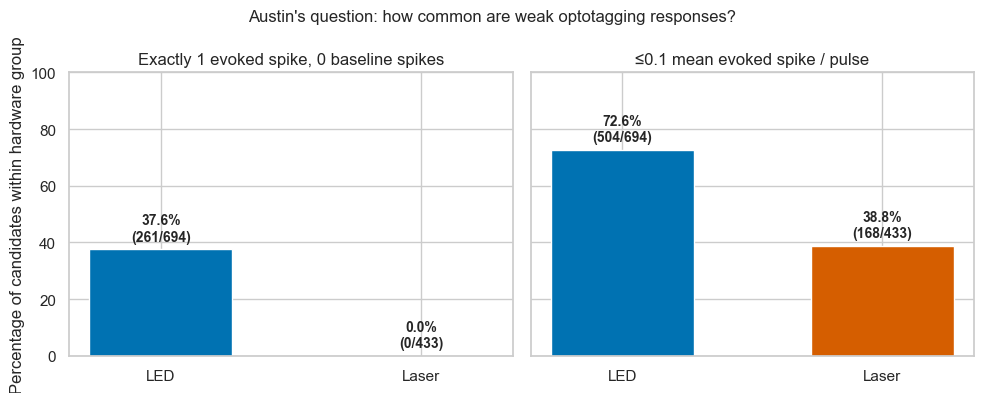

In [5]:
WINDOW_S = 0.008
# Counts are reconstructed from aggregate rates and presentation counts.
# The original processing uses 8-ms baseline and evoked windows.
candidates = candidates.copy()
candidates["evoked_total"] = np.rint(candidates.evoked_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["baseline_total"] = np.rint(candidates.baseline_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["exact_one_zero"] = (candidates.evoked_total == 1) & (candidates.baseline_total == 0)
candidates["mean_spikes_per_pulse"] = candidates.evoked_rate_hz * WINDOW_S
THRESH = 0.10  # Exploratory, NOT a validated candidate exclusion criterion
candidates["weak_per_pulse"] = candidates.mean_spikes_per_pulse <= THRESH

def summarize(flag):
    result = candidates.groupby("hardware").agg(
        total=("unit_id", "size"), matching=(flag, "sum")).reindex(order)
    result["pct"] = 100 * result.matching / result.total
    return result
exact = summarize("exact_one_zero")
comparable = summarize("weak_per_pulse")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)
panels = [
    ("Exactly 1 evoked spike, 0 baseline spikes", exact),
    ("≤0.1 mean evoked spike / pulse", comparable)
]
for ax, (ttl, dat) in zip(axes, panels):
    ax.bar(order, dat.pct, width=.55, color=[colors[h] for h in order])
    for j,h in enumerate(order):
        row = dat.loc[h]
        ax.text(j, row.pct + 2, f"{row.pct:.1f}%\n({int(row.matching)}/{int(row.total)})",
                ha="center", va="bottom", fontsize=10, weight="bold")
    ax.set(title=ttl, xlabel="", ylim=(0, 100))
axes[0].set_ylabel("Percentage of candidates within hardware group")
fig.suptitle("Austin's question: how common are weak optotagging responses?", fontsize=12)
fig.tight_layout()
plt.show()

The exact pattern occurred in **261/694 LED candidates (37.6%)** and **0/433 laser candidates**, because the longer laser-proxy protocols make one spike insufficient to pass the response threshold. With the per-pulse threshold, **72.6% of LED candidates and 38.8% of laser candidates** fell in the weak-response range. This exploratory threshold describes response strength among selected candidates.

**Does the firing-rate difference persist after accounting for Cre line?**
The table shows how many sessions contributed to each Cre-line-supported candidate population. Yield is the percentage of QC-eligible units that met the candidate criteria, and rates give each contributing recording equal weight.

In [6]:
cre_order = ["Pvalb", "Sst", "Vip"]
cre_index = pd.MultiIndex.from_product([cre_order, order], names=["cre_line", "hardware"])
composition = session.groupby(["cre_line", "hardware"]).agg(
    sessions=("ecephys_session_id", "size"), eligible_units=("eligible", "sum"),
    candidate_units=("candidates", "sum"), session_mean_hz=("mean_evoked_hz", "mean"))
composition = composition.reindex(cre_index)
count_cols = ["sessions", "eligible_units", "candidate_units"]
composition[count_cols] = composition[count_cols].fillna(0).astype(int)
composition["yield_pct"] = (100 * composition["candidate_units"]
                            / composition["eligible_units"].replace(0, np.nan))
unit_rates = candidates.groupby(["cre_line", "hardware"])["evoked_rate_hz"].agg(
    unit_mean_hz="mean", unit_median_hz="median")
cre_composition_full = composition.join(unit_rates)
display(cre_composition_full[["sessions", "yield_pct", "session_mean_hz"]].rename(
    columns={"sessions": "Sessions", "yield_pct": "Candidate yield (%)",
             "session_mean_hz": "Mean session rate (Hz)"}).round(2))

Sessions  Candidate yield (%)  Mean session rate (Hz)
cre_line hardware                                                       
Pvalb    LED              4                13.97                   13.62
         Laser            4                17.55                   64.86
Sst      LED              8                17.25                   11.34
         Laser            4                 9.77                   53.17
Vip      LED              3                15.71                    8.82
         Laser            5                 5.94                   20.70

**Evoked firing rates within each Cre line**
Within Pvalb, Sst, and Vip candidate populations, compare session means on a shared vertical scale. Diamonds and whiskers show group means and 95% confidence intervals.

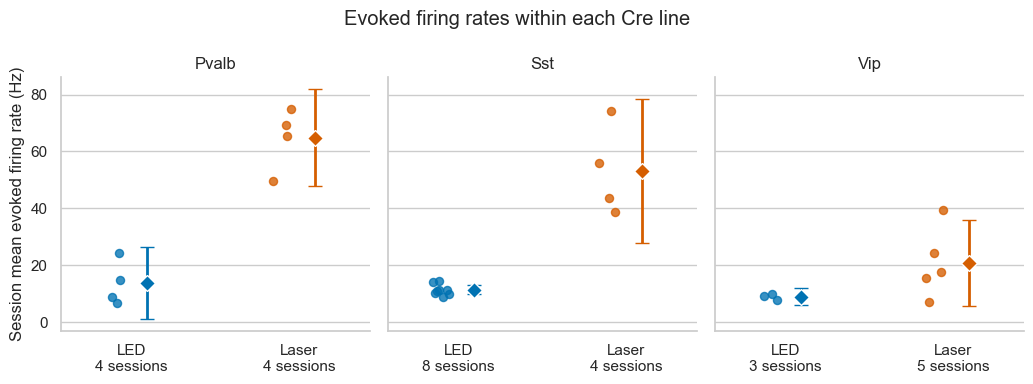

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.9), sharey=True)
cre_rng = np.random.default_rng(42)
for ax, cre in zip(axes, cre_order):
    plot_session_rates(ax, rate_sessions.loc[rate_sessions.cre_line.eq(cre)], cre_rng)
    ax.set_title(cre)
axes[0].set_ylabel("Session mean evoked firing rate (Hz)")
fig.suptitle("Evoked firing rates within each Cre line")
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

Laser-proxy session means were higher in all three Cre-line-supported candidate populations. The Vip contrast was smaller, and its exploratory 95% interval included zero. The small strata limit comparisons among Cre lines.

**Supporting checks and model details**
Expand the outputs for the candidate-rule audit, session-rate diagnostics and exact test results, session omissions, protocol checks, full composition table, and Cre-line-adjusted model. LED-proxy session means are right-skewed, while laser-proxy session means have a wider spread. Each recording represents a distinct specimen.

Candidate rates available for 28/28 sessions.
28 distinct specimens across 28 recording sessions.

Session mean rates (Hz) and sample skewness
           n    mean      sd  median  minimum  maximum   skew     iqr
hardware                                                             
LED       15  11.445   4.297  10.043    6.699   24.369  2.087   3.827
Laser     13  44.279  23.250  43.778    6.954   74.859 -0.160  41.367


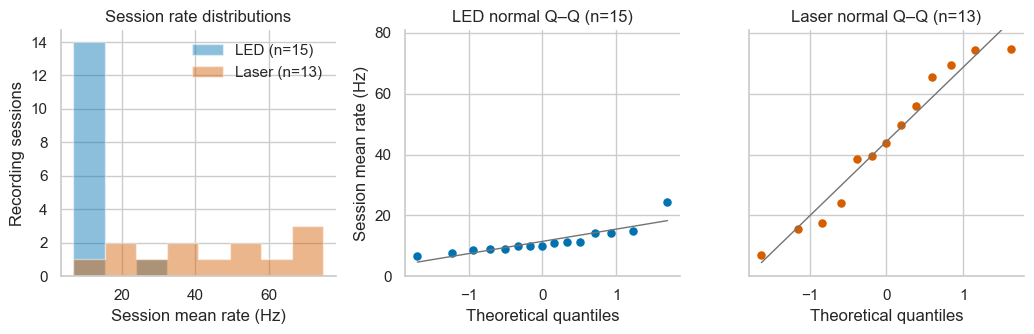

Welch comparison (LED − laser)
difference_hz      -32.83443
ci_low_hz          -47.00273
ci_high_hz         -18.66613
df                  12.71141
t                  -5.018141
p               0.0002518735

Mann–Whitney U (LED group) = 17, p = 0.0002284984


In [8]:
# Upstream evoked window: +1 to +9 ms. Baseline window: −10 to −2 ms.
# Rates are mean spikes per pulse divided by 0.008 s. Audit saved flags.
saved_flag = df["candidate_tagged"].astype(str).str.lower().isin(["true", "1"])
response_pass = df["evoked_rate_hz"].div(df["baseline_rate_hz"] + 1).gt(2)
qc_pass = (df["presence_ratio"].ge(.95) & df["isi_violations"].le(.5)
           & df["amplitude_cutoff"].le(.1) & df["snr"].ge(1))
assert saved_flag.equals(response_pass)
assert df["snr_qc"].equals(qc_pass)
assert df["matched_candidate"].equals(response_pass & qc_pass)

session_fields = ["specimen_id", "cre_line", "n_pulses"]
assert df.groupby("ecephys_session_id")[session_fields].nunique(dropna=False).eq(1).all().all()
specimens = df.groupby("ecephys_session_id")["specimen_id"].first()
assert specimens.notna().all() and specimens.is_unique
print(f"Candidate rates available for {len(rate_sessions)}/{len(session)} sessions.")
print(f"{len(specimens)} distinct specimens across {len(session)} recording sessions.")

rate_description = rate_sessions.groupby("hardware")["mean_evoked_hz"].agg(
    n="size", mean="mean", sd="std", median="median", minimum="min",
    maximum="max", skew="skew").reindex(order)
rate_description["iqr"] = rate_sessions.groupby("hardware")["mean_evoked_hz"].agg(
    lambda rates: rates.quantile(.75) - rates.quantile(.25))
print("\nSession mean rates (Hz) and sample skewness")
print(rate_description.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))
rate_bins_shared = np.histogram_bin_edges(rate_sessions["mean_evoked_hz"], bins=8)
for h, ax in zip(order, axes[1:]):
    values = rate_groups[h]
    axes[0].hist(values, bins=rate_bins_shared, histtype="stepfilled",
                 color=colors[h], alpha=.45, label=f"{h} (n={len(values)})")
    (quantiles, ordered), (slope, intercept, _) = stats.probplot(values, dist="norm")
    ax.scatter(quantiles, ordered, color=colors[h], s=26)
    ax.plot(quantiles, intercept + slope * quantiles, color="0.45", linewidth=1)
    ax.set(title=f"{h} normal Q–Q (n={len(values)})", xlabel="Theoretical quantiles",
           ylim=(0, 1.08 * rate_sessions["mean_evoked_hz"].max()))
axes[0].set(title="Session rate distributions", xlabel="Session mean rate (Hz)",
            ylabel="Recording sessions")
axes[0].legend(frameon=False)
axes[1].set_ylabel("Session mean rate (Hz)")
axes[2].tick_params(labelleft=False)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()
print("Welch comparison (LED − laser)")
print(pd.Series(welch_rates).to_string(float_format=lambda value: f"{value:.7g}"))
print(f"\nMann–Whitney U (LED group) = {rank_rates.statistic:g}, p = {rank_rates.pvalue:.7g}")

In [9]:
def compare_session_subset(rows):
    return welch_session_comparison(
        rows.loc[rows.hardware.eq("LED"), "mean_evoked_hz"],
        rows.loc[rows.hardware.eq("Laser"), "mean_evoked_hz"],
    )


leave_one_out = pd.DataFrame({
    sid: compare_session_subset(rate_sessions.loc[rate_sessions.ecephys_session_id.ne(sid)])
    for sid in rate_sessions["ecephys_session_id"]
}).T.rename_axis("omitted_session")
print("Leave-one-session-out ranges")
print(leave_one_out[["difference_hz", "ci_high_hz", "p"]].agg(["min", "max"]).to_string())
most_influential = leave_one_out["difference_hz"].sub(welch_rates["difference_hz"]).abs().idxmax()
print(f"Largest shift in the mean difference after omitting session {most_influential}.")

top_laser = rate_sessions.loc[rate_sessions.hardware.eq("Laser")].nlargest(2, "mean_evoked_hz")
trimmed_welch = compare_session_subset(rate_sessions.drop(top_laser.index))
print(f"\nOmit the two highest-rate laser sessions ({', '.join(top_laser.ecephys_session_id.astype(str))})")
print(pd.Series(trimmed_welch).to_string(float_format=lambda value: f"{value:.7g}"))

count_rows = []
for h, group in rate_sessions.groupby("hardware", sort=False):
    count_rows.append({
        "hardware": h,
        "candidate_min": group["candidates"].min(),
        "candidate_median": group["candidates"].median(),
        "candidate_max": group["candidates"].max(),
        "equal_session_mean_hz": group["mean_evoked_hz"].mean(),
        "candidate_weighted_mean_hz": np.average(group["mean_evoked_hz"], weights=group["candidates"]),
        "count_rate_spearman_rho": stats.spearmanr(group["candidates"], group["mean_evoked_hz"]).statistic,
    })
print("\nCandidate counts and descriptive weighting sensitivity")
print(pd.DataFrame(count_rows).set_index("hardware").reindex(order).round(3).to_string())

print("\nNumber of sessions by stimulation presentation count")
print(pd.crosstab(rate_sessions.hardware, rate_sessions.n_pulses).reindex(order).to_string())

protocol = pd.read_csv(ROOT / "opto_protocol_summary.csv")
protocol_by_hardware = rate_sessions.merge(
    protocol, on=["ecephys_session_id", "cre_line"], how="left", validate="one_to_one")
assert protocol_by_hardware["ten_ms_pulses"].eq(protocol_by_hardware["n_pulses"]).all()
print("\nSession counts by saved light-level settings (calibration unresolved)")
print(pd.crosstab(protocol_by_hardware.hardware, protocol_by_hardware.light_levels).reindex(order).to_string())

Leave-one-session-out ranges
     difference_hz  ci_high_hz         p
min     -35.944876  -22.312706  0.000099
max     -30.286116  -16.001478  0.000744
Largest shift in the mean difference after omitting session 816200189.

Omit the two highest-rate laser sessions (829720705, 839068429)
difference_hz     -27.31845
ci_low_hz         -41.37178
ci_high_hz        -13.26512
df                  10.6305
t                 -4.296738
p               0.001364823

Candidate counts and descriptive weighting sensitivity
          candidate_min  candidate_median  candidate_max  equal_session_mean_hz  candidate_weighted_mean_hz  count_rate_spearman_rho
hardware                                                                                                                            
LED                  22              44.0             69                 11.445                      11.179                    0.088
Laser                 5              27.0             64                 44.279          

In [10]:
import statsmodels.formula.api as smf

print(cre_composition_full.round(3).to_string())

cre_overlap = (pd.crosstab(rate_sessions["cre_line"], rate_sessions["hardware"])
               .reindex(index=cre_order, columns=order, fill_value=0))
print("\nSessions with candidate rates by Cre line")
print(cre_overlap.to_string())
assert cre_overlap.gt(0).all().all(), "A Cre line lacks hardware overlap"
model = smf.ols(
    'mean_evoked_hz ~ C(hardware, Treatment(reference="Laser"))'
    ' + C(cre_line, Treatment(reference="Pvalb"))',
    data=rate_sessions,
)
assert len(model.endog) == len(rate_sessions)
model_rank = np.linalg.matrix_rank(model.exog)
assert model_rank == model.exog.shape[1], "The model design is rank deficient"
adjusted = model.fit(cov_type="HC3", use_t=True)
hardware_term = 'C(hardware, Treatment(reference="Laser"))[T.LED]'
adjusted_difference = adjusted.params[hardware_term]
ci_low, ci_high = adjusted.conf_int().loc[hardware_term]
print(f"\nEqual-session OLS with HC3 SEs (n={int(adjusted.nobs)}, design rank={model_rank}, "
      f"residual df={adjusted.df_resid:g})")
print(f"LED − laser adjusted for Cre line: {adjusted_difference:.4f} Hz "
      f"(95% CI {ci_low:.4f} to {ci_high:.4f}, p={adjusted.pvalues[hardware_term]:.7g})")
print(f"Adjusted minus unadjusted contrast: {adjusted_difference - welch_rates['difference_hz']:+.4f} Hz")

within_cre = pd.DataFrame({
    cre: compare_session_subset(rows)
    for cre, rows in rate_sessions.groupby("cre_line")
    if cre_overlap.loc[cre].ge(3).all()
}).T.reindex(cre_order)
print("\nExploratory within-Cre differences (LED − laser, unadjusted 95% CIs)")
print(within_cre.reindex(columns=["difference_hz", "ci_low_hz", "ci_high_hz"]).round(3).to_string())

                   sessions  eligible_units  candidate_units  session_mean_hz  yield_pct  unit_mean_hz  unit_median_hz
cre_line hardware                                                                                                     
Pvalb    LED              4             981              137           13.622     13.965        12.875           8.333
         Laser            4            1185              208           64.857     17.553        66.683          49.167
Sst      LED              8            2353              406           11.339     17.255        11.494           5.556
         Laser            4            1320              129           53.173      9.773        50.633          20.000
Vip      LED              3             961              151            8.823     15.713         8.793           5.556
         Laser            5            1615               96           20.701      5.944        22.567           6.667

Sessions with candidate rates by Cre line
hardw

**Interpretation for Liz and Austin**
Laser-proxy sessions had higher observed evoked firing rates among matched candidates. The LED-minus-laser difference remained negative after every single-session omission and after omitting the two highest-rate laser sessions. Cre-line adjustment gave **−36.12 Hz** (HC3 95% CI −48.21 to −24.03), close to the unadjusted **−32.83 Hz**.

The hardware proxy is unverified, and adjustment leaves recording era, optical power, stimulation settings, and response-based candidate selection unresolved. The association provides insufficient evidence about causal hardware effects or biological tagging validity to justify excluding either group.

## Waveform morphology across optotagging candidate classes

Do Pvalb, Sst, and Vip optotagging candidates in visual cortex differ in extracellular spike shape? Compare peak-channel mean waveforms from up to 15 candidates per Cre line, sampling up to five units per recording session. The saved `matched_candidate` flag defines provisional candidate membership. Align traces at the negative trough and divide by its magnitude to compare shape across amplitudes.

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

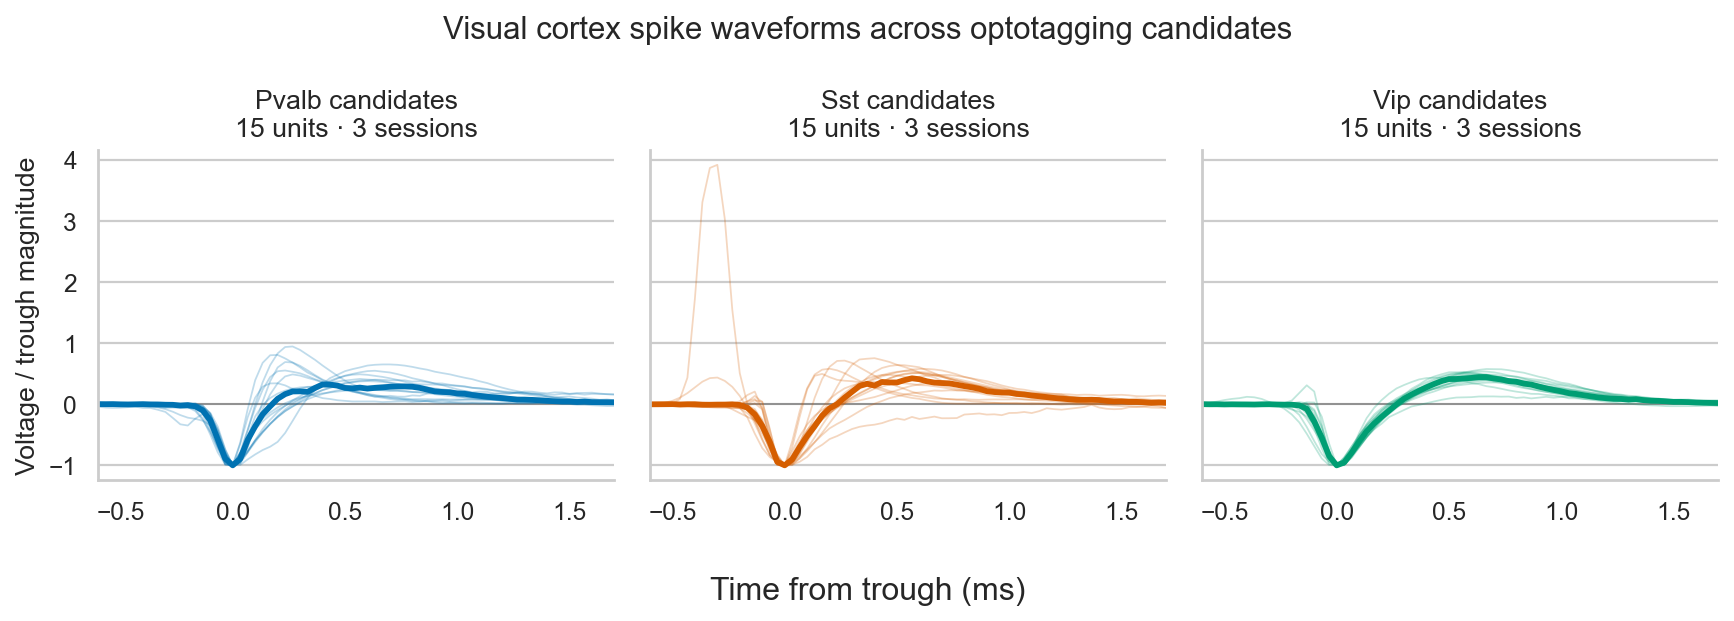

In [11]:
from collections import Counter
from pathlib import Path
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from allensdk.brain_observatory.ecephys.ecephys_session import EcephysSession
from allensdk.brain_observatory.ecephys.ecephys_session_api.ecephys_nwb_session_api import (
    EcephysNwbSessionApi,
)
from pynwb import NWBHDF5IO


def aligned_peak_trace(unit_id, units, waveforms):
    if unit_id not in units.index or unit_id not in waveforms:
        raise ValueError("unit or mean waveform missing")
    peak_channel = units.at[unit_id, "peak_channel_id"]
    try:
        trace = waveforms[unit_id].sel(channel_id=peak_channel)
    except KeyError as exc:
        raise ValueError("peak channel missing") from exc

    voltage = np.asarray(trace.values, dtype=float)
    if "time" not in trace.coords:
        raise ValueError("time coordinates missing")
    time_ms = np.asarray(trace["time"].values, dtype=float) * 1000
    if (voltage.shape != time_ms.shape or voltage.ndim != 1 or voltage.size < 3
            or not np.isfinite(voltage).all() or not np.isfinite(time_ms).all()
            or not (np.diff(time_ms) > 0).all()):
        raise ValueError("invalid voltage or time coordinates")

    trough = int(np.argmin(voltage))
    if trough in (0, voltage.size - 1) or voltage[trough] >= 0:
        raise ValueError("no interior negative trough")
    return time_ms - time_ms[trough], voltage / abs(voltage[trough])


def sample_waveforms(pool, cache_dir, rng, target=15, per_session=5):
    groups = pool.groupby("ecephys_session_id", sort=True)
    sampled, skipped = [], Counter()
    for session_id in rng.permutation(list(groups.groups)):
        nwb_path = cache_dir / f"session_{session_id}" / f"session_{session_id}.nwb"
        if not nwb_path.is_file():
            skipped["session NWB missing"] += 1
            continue

        unit_ids = rng.permutation(np.sort(groups.get_group(session_id)["unit_id"]))
        session_count = 0
        # Buffer one read-only session at a time to avoid repeated reads from the drive.
        try:
            with (h5py.File(nwb_path, "r", driver="core", backing_store=False) as h5,
                  NWBHDF5IO(file=h5, mode="r", load_namespaces=True) as io):
                ecephys = EcephysSession(api=EcephysNwbSessionApi.from_nwbfile(io.read()))
                units, waveforms = ecephys.units, ecephys.mean_waveforms
                for unit_id in unit_ids:
                    try:
                        time_ms, voltage = aligned_peak_trace(unit_id, units, waveforms)
                    except ValueError as exc:
                        skipped[str(exc)] += 1
                        continue
                    sampled.append((session_id, unit_id, time_ms, voltage))
                    session_count += 1
                    if session_count == per_session or len(sampled) == target:
                        break
                del units, waveforms, ecephys
        except OSError as exc:
            skipped["session NWB unreadable"] += 1
            print(f"Session {session_id}: {exc}")
        if len(sampled) == target:
            break
    return sampled, skipped


waveform_root = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
opto = pd.read_csv(waveform_root / "opto_results" / "all_opto_unit_results.csv")
matched = opto["matched_candidate"].astype(str).str.strip().str.lower().isin(["true", "1"])
visual_candidates = opto.loc[matched & opto["region"].str.startswith("VIS", na=False)]
waveform_colors = {"Pvalb": "#0072B2", "Sst": "#D55E00", "Vip": "#009E73"}
waveform_rng = np.random.default_rng(42)
waveform_samples = {}
for candidate_class in waveform_colors:
    pool = visual_candidates.loc[visual_candidates["cre_line"].eq(candidate_class)]
    sampled, skipped = sample_waveforms(
        pool, waveform_root / "allen_visual_coding_data", waveform_rng
    )
    waveform_samples[candidate_class] = sampled
    if skipped or len(sampled) < 15:
        print(f"{candidate_class}: {len(sampled)}/15 usable waveforms. Skipped: {dict(skipped)}")

# Use only the time range shared by every trace, with no extrapolation.
aligned_times = [time for rows in waveform_samples.values() for _, _, time, _ in rows]
if not aligned_times:
    raise RuntimeError("No usable visual-cortex waveforms in the local Allen cache.")
left = max(time[0] for time in aligned_times)
right = min(time[-1] for time in aligned_times)
step = max(np.median(np.diff(time)) for time in aligned_times)
grid_ms = step * np.arange(np.ceil(left / step), np.floor(right / step) + 1)
if grid_ms.size < 3:
    raise RuntimeError("Too few shared time samples for waveform comparison.")

sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharex=True, sharey=True, dpi=160)
for ax, (candidate_class, color) in zip(axes, waveform_colors.items()):
    rows = waveform_samples[candidate_class]
    n_sessions = len({session_id for session_id, _, _, _ in rows})
    ax.axhline(0, color="0.55", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    if rows:
        traces = np.array([np.interp(grid_ms, time, voltage) for _, _, time, voltage in rows])
        ax.plot(grid_ms, traces.T, color=color, linewidth=0.8, alpha=0.25)
        ax.plot(grid_ms, np.median(traces, axis=0), color=color, linewidth=2.6)
    else:
        ax.text(0.5, 0.5, "No usable waveforms", ha="center", transform=ax.transAxes)
    session_label = "session" if n_sessions == 1 else "sessions"
    ax.set(title=f"{candidate_class} candidates\n{len(rows)} units · {n_sessions} {session_label}",
           xlim=(grid_ms[0], grid_ms[-1]))

axes[0].set_ylabel("Voltage / trough magnitude")
fig.supxlabel("Time from trough (ms)")
fig.suptitle("Visual cortex spike waveforms across optotagging candidates", fontsize=14)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

- Pvalb: The median waveform has a relatively rapid recovery after the negative trough, consistent with the shorter-duration waveforms we've previously observed. There's also considerable variability in the positive rebound.
- Sst: The median waveform appears broader, with a later positive peak. One individual waveform has an unusually large positive deflection before the trough, which is worth investigating.
- Vip: The individual waveforms look relatively consistent, with a broad positive rebound and less obvious variability than the other two groups.